# How well do GPT-2 features predict cortical fMRI responses during story listening?

| | |
| --- | --- |
| **Question** | Across the whole cortex, how well does a linear mapping from GPT-2 features predict one listener's fMRI responses to stories held out from training, and does it depend on the features arriving at the right moment? |
| **Requires** | The LeBel 2023 data for participant UTS03 (about 750 MB, downloaded by Brain-Score on first use), GPT-2 weights from Hugging Face, about 16 GB of memory. A few minutes per run on a GPU; two runs. |
| **Lessons used** | [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb), [5. Layers and regions](../lessons/05_layers_and_regions.ipynb) |

## Background

Encoding models predict brain responses from features computed by a model of the stimulus. For natural language, features from language models predict fMRI responses in a distributed set of cortical areas during story listening. The LeBel et al. (2023) dataset ([doi:10.1038/s41597-023-02437-z](https://doi.org/10.1038/s41597-023-02437-z)) contains fMRI from participants who listened to hours of spoken stories, so a mapping can be fitted on some stories and tested on others.

Features can predict a response for the wrong reason: slow drifts shared by a whole story, or properties of the words that do not depend on when they were heard. The control here keeps every feature vector but scrambles their order within each story, so a feature no longer lines up with the moment its word was heard.

## Hypothesis

Features from GPT-2 layer `h.11` predict held-out responses with a positive correlation at most cortical locations. The median over all locations is small (below 0.2), because most locations are not driven by language and there is no correction for measurement noise. With word order scrambled within stories, prediction falls towards zero.

## Method

**Data.** One participant (UTS03), 25 stories, 8,964 fMRI samples (TR = 2 s), 52,904 spoken words. Targets are 20,484 cortical surface locations (vertices) on the fsaverage5 surface, 10,242 per hemisphere.

**Features.** Each word is presented to GPT-2 with up to 32 preceding words of context, and layer `h.11` is recorded. That layer was chosen on a different dataset (Pereira 2018), not on this one.

**Benchmark** (`LeBel2023-UTS03-encoding`, registered defaults):

- Word features are resampled onto the fMRI sampling grid with a Lanczos filter.
- Features delayed by 1 to 4 samples are concatenated, so the regression can model the slow blood-oxygen response.
- Each vertex is standardized within each story.
- Ridge regression is fit with five folds that hold out whole stories.
- Each vertex's score is the Pearson correlation between predicted and measured responses on held-out stories. The benchmark reports the median over vertices, with no noise-ceiling normalization.

**Control.** The same benchmark, with the resampled features permuted in time within each story before fitting.

## Setup

Imports, a check that the LeBel assembly is available, and the fsaverage5 surface used for the map (downloaded by nilearn on first use).

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from nilearn import datasets, plotting
import brainscore

fsaverage = datasets.fetch_surf_fsaverage(mesh='fsaverage5')     # cortical surface for the map

## The subject

The registered GPT-2. The benchmark records its layer `h.11`, the layer its registration uses for the language system.

In [2]:
model = brainscore.load_model('gpt2')

## The experiment

### Stimuli and recordings

The registered benchmark holds the stories, their word timings and the participant's fMRI. It builds the word-by-word stimuli, records the subject, and fits and tests the regression.

In [3]:
benchmark = brainscore.load_benchmark('LeBel2023-UTS03-encoding')

### Task

Plain listening: each word is presented once, with its preceding context, and the language layer is recorded. There is no answer to give.

### Controls

The control subclasses the registered benchmark and changes one step: the features it hands to the regression. Everything else, including the folds and the ridge penalty search, is the benchmark's own.

In [4]:
from brainscore.benchmarks.lebel2023.benchmark import LeBel2023EncodingWordLevel

class TimingShuffled(LeBel2023EncodingWordLevel):
    """Same features and stories; their order scrambled within each story."""
    def _model_features(self, candidate, stimulus_set, assembly):
        features = super()._model_features(candidate, stimulus_set, assembly)
        stories = np.asarray(assembly['story_id'].values)
        rng = np.random.default_rng(1234)                       # one fixed permutation per story
        shuffled = features.copy()
        for story in np.unique(stories):
            rows = np.flatnonzero(stories == story)             # this story's fMRI samples
            shuffled[rows] = features[rng.permutation(rows)]
        return shuffled

## Run

Each benchmark runs the subject through the stories and returns a score.

In [5]:
score = benchmark(model)

control_benchmark = TimingShuffled(identifier='LeBel2023-UTS03-encoding-timing-shuffled', pooling='lanczos')
control = control_benchmark(model)

Activation cache bypassed: unsupported torch.dtype; define cache_config()


Activation cache bypassed: unsupported torch.dtype; define cache_config()


## Read results back

Besides the median, each score keeps one held-out correlation per vertex (`raw`, in assembly order) and, when the benchmark keeps only some vertices, their positions on the surface (`target_index`).

In [6]:
gpt2_r = np.asarray(score.attrs['raw'])
shuffled_r = np.asarray(control.attrs['raw'])
target_index = score.attrs['target_index']
print(f'GPT-2 h.11: median r = {float(score):.4f} over {len(gpt2_r):,} vertices')
print(f'timing-shuffled: median r = {float(control):.4f}')

GPT-2 h.11: median r = 0.1013 over 20,484 vertices
timing-shuffled: median r = 0.0023


## Analysis

In [7]:
def summary(label, r):
    """Distribution of per-vertex correlations, ignoring vertices without a value."""
    r = r[np.isfinite(r)]
    return (f'{label:16s} median {np.median(r):+.4f}  mean {r.mean():+.4f}  r > 0 at {np.mean(r > 0):.1%}  '
            f'5th-95th {np.percentile(r, 5):+.3f} to {np.percentile(r, 95):+.3f}  max {r.max():.3f}')

def on_surface(r, index):
    """Place per-vertex values on the 20,484 fsaverage5 vertices; vertices without a value are NaN."""
    surface = np.full(20484, np.nan)
    surface[np.arange(len(r)) if index is None else np.asarray(index)] = r
    return surface

## Results

In [8]:
print(summary('GPT-2 h.11', gpt2_r))
print(summary('timing-shuffled', shuffled_r))
print(f'GPT-2 beats its own shuffled control at {np.mean(gpt2_r > shuffled_r):.1%} of vertices')

GPT-2 h.11       median +0.1013  mean +0.1134  r > 0 at 95.3%  5th-95th +0.002 to +0.273  max 0.543
timing-shuffled  median +0.0023  mean +0.0025  r > 0 at 56.3%  5th-95th -0.023 to +0.028  max 0.078
GPT-2 beats its own shuffled control at 94.7% of vertices


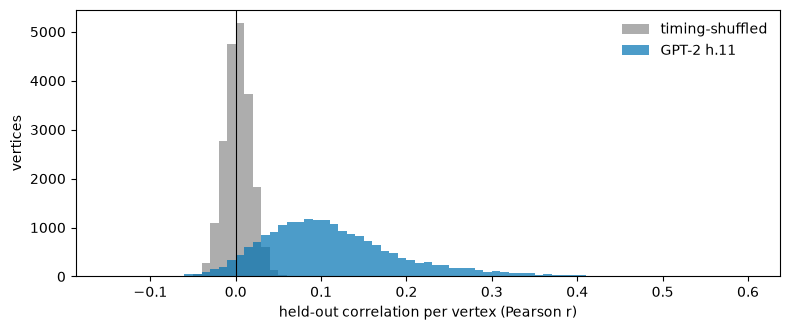

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(-0.15, 0.6, 76)
ax.hist(shuffled_r[np.isfinite(shuffled_r)], bins=bins, color='0.6', alpha=0.8, label='timing-shuffled')
ax.hist(gpt2_r[np.isfinite(gpt2_r)], bins=bins, color='#0072B2', alpha=0.7, label='GPT-2 h.11')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('held-out correlation per vertex (Pearson r)'); ax.set_ylabel('vertices')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

The map places each vertex's GPT-2 correlation on the inflated cortical surface. It is a map of prediction accuracy, not of brain activity.

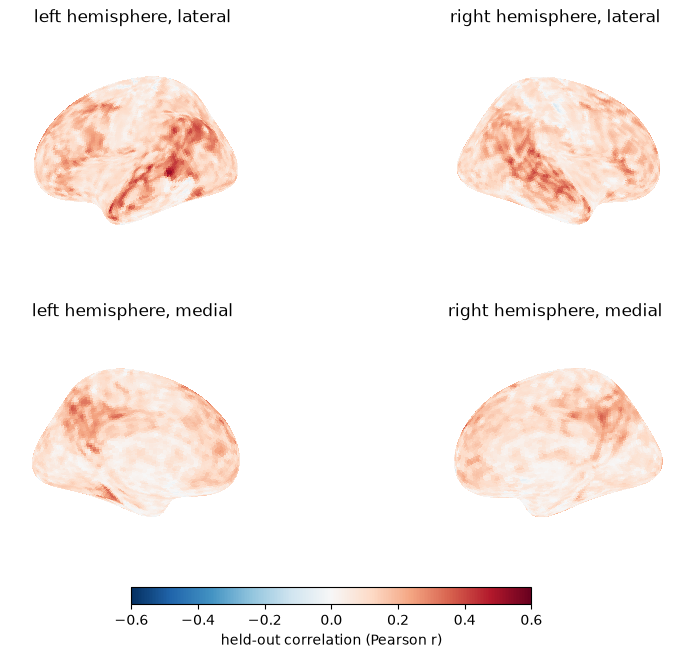

In [10]:
surface = on_surface(gpt2_r, target_index)
limit = float(np.ceil(np.nanmax(np.abs(surface)) * 10) / 10)    # symmetric color range, rounded up to 0.1
fig = plt.figure(figsize=(10, 7))
for number, (hemi, view) in enumerate([('left', 'lateral'), ('right', 'lateral'), ('left', 'medial'), ('right', 'medial')]):
    ax = fig.add_subplot(2, 2, number + 1, projection='3d')
    half = surface[:10242] if hemi == 'left' else surface[10242:]   # the first 10,242 vertices are the left hemisphere
    plotting.plot_surf_stat_map(fsaverage[f'infl_{hemi}'], half, hemi=hemi, view=view,
                                bg_map=fsaverage[f'sulc_{hemi}'], cmap='RdBu_r', threshold=None,
                                vmin=-limit, vmax=limit, colorbar=False, axes=ax, figure=fig)
    ax.set_title(f'{hemi} hemisphere, {view}')
color_axis = fig.add_axes([0.3, 0.06, 0.4, 0.025])
fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-limit, limit), cmap='RdBu_r'), cax=color_axis,
             orientation='horizontal').set_label('held-out correlation (Pearson r)')
plt.show()

## Conclusion and limits

GPT-2 layer `h.11` predicted held-out story responses with a median correlation of 0.101 across 20,484 vertices, positive at 95% of them, and up to 0.54 at the best vertex. The highest values lie along the superior temporal and inferior frontal cortex of both hemispheres, the regions usually described as the language network. With word order scrambled within each story, the median fell to 0.002 and the best vertex to 0.08; GPT-2 beat its own scrambled control at 95% of vertices. The prediction therefore depends on the features arriving when their words were heard, not on story-level properties of the features. The result supports the hypothesis.

Limits:

- One participant. The result does not establish generalization across people.
- There is no repeat-based noise ceiling, so model error and measurement noise are not separated, and the median includes vertices that do not respond to speech at all.
- One layer, chosen on another dataset; other layers may predict better.
- One permutation of the control; its distribution would need several seeds.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)